# 模型 A 正式版：仅音韵特征的 Ridge / Formal Model A: Phonological Ridge

本 Notebook 检验：**只从普通词学到的音韵—感官映射，能否迁移到未见过的日语拟声拟态词；加入 16 或 32 个拟声拟态词后是否改善。**

它保留 396 个普通词和 108 个拟声拟态词，比较平均值基准、仅音拍数、普通词中可学习的音韵特征、全部 12 个音韵特征。六个感官维度分别选择 Ridge 正则强度。

This notebook tests whether phonology-to-sensory mappings learned from ordinary Japanese words transfer to held-out ideophones, and whether 16 or 32 labeled ideophones improve prediction.

> 当前 `family_id` 尚未人工确认，因此运行结果会明确标记为 **provisional**。填写 `data/review/ideophone_family_review.xlsx` 并把确认结果写回主表后，才生成论文最终数字。


In [1]:
from pathlib import Path
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", context="notebook")

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROJECT_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "japanese_sensory_modeling.csv"
COLAB_DATA_PATH = Path("/content/japanese_sensory_modeling.csv")
DATA_PATH = PROJECT_DATA_PATH if PROJECT_DATA_PATH.exists() else COLAB_DATA_PATH

RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "找不到数据。若在 Colab 运行，请上传 japanese_sensory_modeling.csv 到 /content。"
    )

# 正式运行默认使用 20 个固定种子。只检查代码时，可先设置环境变量 MODEL_A_FAST=1。
FAST_MODE = os.getenv("MODEL_A_FAST", "0") == "1"
FULL_SUPPORT_SEEDS = [
    13, 29, 47, 71, 101, 131, 173, 211, 257, 307,
    359, 401, 449, 503, 557, 613, 673, 733, 797, 863,
]
SUPPORT_SEEDS = FULL_SUPPORT_SEEDS[:2] if FAST_MODE else FULL_SUPPORT_SEEDS
SUPPORT_SIZES = [0, 16, 32]
ALPHAS = np.array([1e-8, 1e-2, 1e2, 1e8]) if FAST_MODE else np.logspace(-8, 8, 25)
N_BOOTSTRAP = 200 if FAST_MODE else 2000
N_PERMUTATIONS = 1000 if FAST_MODE else 10000

print(f"Data: {DATA_PATH}")
print(f"Mode: {'FAST CHECK' if FAST_MODE else 'FORMAL'}")
print(f"Support seeds: {len(SUPPORT_SEEDS)}, alphas: {len(ALPHAS)}")


Data: /Users/Nathan/Documents/ChatGPT/日语拟声词/data/processed/japanese_sensory_modeling.csv
Mode: FORMAL
Support seeds: 20, alphas: 25


## 1. 读取数据并确定词族状态 / Load data and determine family status


In [2]:
data = pd.read_csv(DATA_PATH)
primary = data.loc[data["use_in_primary_analysis"] == 1].copy()
ordinary = primary.loc[primary["is_ideophone"] == 0].copy()
ideophones = primary.loc[primary["is_ideophone"] == 1].copy()

assert len(data) == 510
assert len(primary) == 504
assert len(ordinary) == 396
assert len(ideophones) == 108

family_confirmed = (
    ideophones["family_id"].notna().all()
    and ideophones["family_review_status"].eq("confirmed").all()
    and "outer_fold_final" in ideophones.columns
    and ideophones["outer_fold_final"].notna().all()
)

if family_confirmed:
    FAMILY_COLUMN = "family_id"
    FOLD_COLUMN = "outer_fold_final"
    ANALYSIS_STATUS = "final_confirmed_families"
else:
    FAMILY_COLUMN = "family_candidate_key"
    FOLD_COLUMN = "outer_fold_provisional"
    ANALYSIS_STATUS = "provisional_candidate_families"

assert set(ideophones[FOLD_COLUMN].astype(int)) == {1, 2, 3}
assert ideophones.groupby(FAMILY_COLUMN)[FOLD_COLUMN].nunique().max() == 1

print({
    "all_rows": len(data),
    "primary_rows": len(primary),
    "ordinary": len(ordinary),
    "ideophones": len(ideophones),
    "ideophone_families": ideophones[FAMILY_COLUMN].nunique(),
    "analysis_status": ANALYSIS_STATUS,
})


{'all_rows': 510, 'primary_rows': 504, 'ordinary': 396, 'ideophones': 108, 'ideophone_families': 103, 'analysis_status': 'provisional_candidate_families'}


## 2. 输入、预测目标与分布检查 / Features, targets and distribution shift


In [3]:
FULL_FEATURES = [
    "feature_mora_count",
    "feature_full_reduplication",
    "feature_sokuon_count",
    "feature_moraic_n_count",
    "feature_long_mark_count",
    "feature_voiced_obstruent_mora_count",
    "feature_p_series_mora_count",
    "feature_vowel_a_mora_count",
    "feature_vowel_i_mora_count",
    "feature_vowel_u_mora_count",
    "feature_vowel_e_mora_count",
    "feature_vowel_o_mora_count",
]

LABELS = [
    "visual_mean",
    "auditory_mean",
    "haptic_mean",
    "olfactory_mean",
    "gustatory_mean",
    "interoceptive_mean",
]
DIMENSION_NAMES = [label.removesuffix("_mean") for label in LABELS]

assert primary[FULL_FEATURES + LABELS].notna().all().all()

# “common” 只保留普通词中有变化的特征，避免零样本时用目标域独有特征。
COMMON_FEATURES = [c for c in FULL_FEATURES if ordinary[c].nunique() > 1]
MODEL_FEATURES = {
    "mean_baseline": [],
    "ridge_mora_only": ["feature_mora_count"],
    "ridge_phonology_common": COMMON_FEATURES,
    "ridge_phonology_full": FULL_FEATURES,
}

shift_rows = []
for feature in FULL_FEATURES:
    source = ordinary[feature].astype(float)
    target = ideophones[feature].astype(float)
    source_sd = source.std(ddof=1)
    outside = (target < source.min()) | (target > source.max())
    shift_rows.append({
        "feature": feature,
        "ordinary_mean": source.mean(),
        "ordinary_sd": source_sd,
        "ordinary_min": source.min(),
        "ordinary_max": source.max(),
        "ideophone_mean": target.mean(),
        "ideophone_sd": target.std(ddof=1),
        "ideophone_min": target.min(),
        "ideophone_max": target.max(),
        "standardized_mean_difference": (
            (target.mean() - source.mean()) / source_sd if source_sd > 0 else np.nan
        ),
        "ideophones_outside_ordinary_range_n": int(outside.sum()),
        "ideophones_outside_ordinary_range_pct": float(outside.mean() * 100),
        "available_in_zero_shot": bool(source.nunique() > 1),
    })

feature_shift = pd.DataFrame(shift_rows)
feature_shift.to_csv(RESULTS_DIR / "model_a_feature_shift.csv", index=False)

print("Common-support features:", COMMON_FEATURES)
feature_shift[[
    "feature", "ordinary_sd", "standardized_mean_difference",
    "ideophones_outside_ordinary_range_n", "available_in_zero_shot"
]]


Common-support features: ['feature_mora_count', 'feature_full_reduplication', 'feature_long_mark_count', 'feature_voiced_obstruent_mora_count', 'feature_p_series_mora_count', 'feature_vowel_a_mora_count', 'feature_vowel_i_mora_count', 'feature_vowel_u_mora_count', 'feature_vowel_e_mora_count', 'feature_vowel_o_mora_count']


,feature,ordinary_sd,standardized_mean_difference,ideophones_outside_ordinary_range_n,available_in_zero_shot
0,feature_mora_count,0.821971,0.688171,0,True
1,feature_full_reduplication,0.131940,3.094195,0,True
2,feature_sokuon_count,0.000000,NaN,34,False
3,feature_moraic_n_count,0.000000,NaN,12,False
4,feature_long_mark_count,0.131940,-0.133975,0,True
5,feature_voiced_obstruent_mora_count,0.504880,0.378461,2,True
6,feature_p_series_mora_count,0.050252,3.450630,3,True
7,feature_vowel_a_mora_count,0.899687,0.022455,6,True
8,feature_vowel_i_mora_count,0.791788,0.347634,0,True
9,feature_vowel_u_mora_count,0.730402,-0.124464,5,True


## 3. 按词族建立 0/16/32 样本划分 / Family-aware 0/16/32 splits


In [4]:
def make_support_order(pool, family_column, seed):
    # Choose one reproducible representative from each shuffled family.
    rng = np.random.default_rng(seed)
    families = np.array(sorted(pool[family_column].astype(str).unique()))
    rng.shuffle(families)
    representatives = []
    for family in families:
        candidates = pool.loc[pool[family_column].astype(str) == family].sort_values("word_id")
        representatives.append(candidates.iloc[int(rng.integers(len(candidates)))])
    return pd.DataFrame(representatives).reset_index(drop=True)


def make_split(frame, test_fold, support_size, seed):
    ordinary_rows = frame.loc[frame["is_ideophone"] == 0].copy()
    target_rows = frame.loc[frame["is_ideophone"] == 1].copy()
    test = target_rows.loc[target_rows[FOLD_COLUMN].astype(int) == int(test_fold)].copy()
    support_pool = target_rows.loc[target_rows[FOLD_COLUMN].astype(int) != int(test_fold)].copy()
    support_order = make_support_order(support_pool, FAMILY_COLUMN, seed)
    support = support_order.head(support_size).copy()
    train = pd.concat([ordinary_rows, support], ignore_index=True)

    assert len(support) == support_size
    assert support[FAMILY_COLUMN].nunique() == support_size
    assert set(train["word_id"]).isdisjoint(set(test["word_id"]))
    assert set(support[FAMILY_COLUMN]).isdisjoint(set(test[FAMILY_COLUMN]))
    return train, test, support


split_specs = []
support_records = []
for test_fold in [1, 2, 3]:
    for support_size in SUPPORT_SIZES:
        seeds = [0] if support_size == 0 else SUPPORT_SEEDS
        for seed in seeds:
            train, test, support = make_split(primary, test_fold, support_size, seed)
            split_id = f"fold{test_fold}_n{support_size}_seed{seed}"
            split_specs.append({
                "split_id": split_id,
                "test_fold": test_fold,
                "support_size": support_size,
                "seed": seed,
                "train": train,
                "test": test,
            })
            for rank, (_, row) in enumerate(support.iterrows(), start=1):
                support_records.append({
                    "analysis_status": ANALYSIS_STATUS,
                    "split_id": split_id,
                    "test_fold": test_fold,
                    "support_size": support_size,
                    "seed": seed,
                    "support_rank": rank,
                    "word_id": row["word_id"],
                    "word_japanese": row["word_japanese"],
                    "evaluation_family": row[FAMILY_COLUMN],
                })

support_samples = pd.DataFrame(support_records)
support_samples.to_csv(RESULTS_DIR / "model_a_support_samples.csv", index=False)

# 同一种子下，16 个词必须是 32 个词的前 16 个；每个支持词来自不同词族。
for fold in [1, 2, 3]:
    for seed in SUPPORT_SEEDS:
        s16 = support_samples.query("test_fold == @fold and seed == @seed and support_size == 16")
        s32 = support_samples.query("test_fold == @fold and seed == @seed and support_size == 32")
        assert s16["word_id"].tolist() == s32.head(16)["word_id"].tolist()
        assert s32["evaluation_family"].nunique() == 32

print(f"Prepared {len(split_specs)} train/test splits")


Prepared 123 train/test splits


## 4. 分维度选择 Ridge 参数并运行全部实验 / Per-dimension tuning and full experiment


In [5]:
def safe_spearman(y_true, y_pred):
    value = spearmanr(y_true, y_pred).statistic
    return float(value) if np.isfinite(value) else np.nan


def fit_ridge_per_dimension(train, test, feature_columns):
    predictions = np.zeros((len(test), len(LABELS)), dtype=float)
    tuning_rows = []
    coefficient_rows = []
    groups = train[FAMILY_COLUMN].fillna(train["word_id"]).astype(str)
    inner_cv = GroupKFold(n_splits=3)

    for dim_index, label in enumerate(LABELS):
        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge()),
        ])
        search = GridSearchCV(
            pipeline,
            param_grid={"ridge__alpha": ALPHAS},
            scoring="neg_mean_absolute_error",
            cv=inner_cv,
            n_jobs=-1,
            refit=True,
        )
        search.fit(train[feature_columns], train[label], groups=groups)
        predictions[:, dim_index] = search.predict(test[feature_columns])
        best_model = search.best_estimator_.named_steps["ridge"]
        tuning_rows.append({
            "dimension": label.removesuffix("_mean"),
            "best_alpha": float(search.best_params_["ridge__alpha"]),
            "inner_cv_mae": float(-search.best_score_),
        })
        for feature, coefficient in zip(feature_columns, best_model.coef_):
            coefficient_rows.append({
                "dimension": label.removesuffix("_mean"),
                "feature": feature,
                "standardized_coefficient": float(coefficient),
            })
    return predictions, tuning_rows, coefficient_rows


prediction_rows = []
metric_rows = []
coefficient_rows = []

for split_number, spec in enumerate(split_specs, start=1):
    train = spec["train"]
    test = spec["test"]
    y_true = test[LABELS].to_numpy(float)

    for model_name, feature_columns in MODEL_FEATURES.items():
        if model_name == "mean_baseline":
            y_pred = np.tile(train[LABELS].mean().to_numpy(float), (len(test), 1))
            tuning = [{"dimension": d, "best_alpha": np.nan, "inner_cv_mae": np.nan}
                      for d in DIMENSION_NAMES]
            coefficients = []
        else:
            y_pred, tuning, coefficients = fit_ridge_per_dimension(train, test, feature_columns)

        tuning_by_dimension = {row["dimension"]: row for row in tuning}
        for dim_index, dimension in enumerate(DIMENSION_NAMES):
            mae = mean_absolute_error(y_true[:, dim_index], y_pred[:, dim_index])
            metric_rows.append({
                "analysis_status": ANALYSIS_STATUS,
                "split_id": spec["split_id"],
                "test_fold": spec["test_fold"],
                "support_size": spec["support_size"],
                "seed": spec["seed"],
                "model": model_name,
                "dimension": dimension,
                "mae": float(mae),
                "spearman": safe_spearman(y_true[:, dim_index], y_pred[:, dim_index]),
                "best_alpha": tuning_by_dimension[dimension]["best_alpha"],
                "inner_cv_mae": tuning_by_dimension[dimension]["inner_cv_mae"],
            })
            for row_index, (_, item) in enumerate(test.iterrows()):
                prediction_rows.append({
                    "analysis_status": ANALYSIS_STATUS,
                    "split_id": spec["split_id"],
                    "test_fold": spec["test_fold"],
                    "support_size": spec["support_size"],
                    "seed": spec["seed"],
                    "model": model_name,
                    "word_id": item["word_id"],
                    "word_japanese": item["word_japanese"],
                    "evaluation_family": item[FAMILY_COLUMN],
                    "dimension": dimension,
                    "y_true": float(y_true[row_index, dim_index]),
                    "y_pred": float(y_pred[row_index, dim_index]),
                    "absolute_error": float(abs(y_true[row_index, dim_index] - y_pred[row_index, dim_index])),
                })

        for coefficient in coefficients:
            coefficient_rows.append({
                "analysis_status": ANALYSIS_STATUS,
                "split_id": spec["split_id"],
                "test_fold": spec["test_fold"],
                "support_size": spec["support_size"],
                "seed": spec["seed"],
                "model": model_name,
                **coefficient,
            })

    if split_number % max(1, len(split_specs) // 10) == 0:
        print(f"Completed {split_number}/{len(split_specs)} splits")

predictions = pd.DataFrame(prediction_rows)
run_metrics = pd.DataFrame(metric_rows)
coefficients = pd.DataFrame(coefficient_rows)

predictions.to_csv(RESULTS_DIR / "model_a_predictions.csv", index=False)
run_metrics.to_csv(RESULTS_DIR / "model_a_run_metrics.csv", index=False)
coefficients.to_csv(RESULTS_DIR / "model_a_coefficients.csv", index=False)

print({
    "prediction_rows": len(predictions),
    "metric_rows": len(run_metrics),
    "coefficient_rows": len(coefficients),
})


Completed 12/123 splits


Completed 24/123 splits


Completed 36/123 splits


Completed 48/123 splits


Completed 60/123 splits


...

Completed 84/123 splits


Completed 96/123 splits


Completed 108/123 splits


Completed 120/123 splits


{'prediction_rows': 106272, 'metric_rows': 2952, 'coefficient_rows': 16974}


## 5. 词族层级置信区间与成对检验 / Family-level intervals and paired tests


In [6]:
# 先在每个词上平均不同少样本种子的误差，再在词族内平均，避免把重复运行当成独立样本。
item_errors = (
    predictions.groupby([
        "model", "support_size", "dimension", "word_id", "evaluation_family"
    ], as_index=False)["absolute_error"].mean()
)
family_errors = (
    item_errors.groupby([
        "model", "support_size", "dimension", "evaluation_family"
    ], as_index=False)["absolute_error"].mean()
)
overall_family_errors = (
    family_errors.groupby([
        "model", "support_size", "evaluation_family"
    ], as_index=False)["absolute_error"].mean()
    .assign(dimension="overall")
)
family_errors_all = pd.concat([family_errors, overall_family_errors], ignore_index=True)


def bootstrap_mean_ci(values, n_bootstrap, seed):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    draws = rng.choice(values, size=(n_bootstrap, len(values)), replace=True).mean(axis=1)
    return float(values.mean()), float(np.quantile(draws, 0.025)), float(np.quantile(draws, 0.975))


summary_rows = []
for group_number, ((model, support_size, dimension), group) in enumerate(
    family_errors_all.groupby(["model", "support_size", "dimension"]), start=1
):
    point, low, high = bootstrap_mean_ci(
        group["absolute_error"], N_BOOTSTRAP, 20261013 + group_number
    )
    summary_rows.append({
        "analysis_status": ANALYSIS_STATUS,
        "model": model,
        "support_size": int(support_size),
        "dimension": dimension,
        "n_families": int(group["evaluation_family"].nunique()),
        "mae": point,
        "ci95_low": low,
        "ci95_high": high,
    })

bootstrap_summary = pd.DataFrame(summary_rows)


def paired_sign_flip_test(differences, n_permutations, seed):
    differences = np.asarray(differences, dtype=float)
    observed = float(differences.mean())
    rng = np.random.default_rng(seed)
    extreme = 0
    completed = 0
    batch_size = 1000
    while completed < n_permutations:
        n_batch = min(batch_size, n_permutations - completed)
        signs = rng.choice([-1.0, 1.0], size=(n_batch, len(differences)))
        null_means = (signs * differences).mean(axis=1)
        extreme += int((np.abs(null_means) >= abs(observed)).sum())
        completed += n_batch
    p_value = (extreme + 1) / (n_permutations + 1)
    return observed, float(p_value)


def bh_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    adjusted = np.empty_like(p_values)
    running = 1.0
    for reverse_rank, index in enumerate(order[::-1], start=1):
        rank = len(p_values) - reverse_rank + 1
        running = min(running, p_values[index] * len(p_values) / rank)
        adjusted[index] = running
    return np.minimum(adjusted, 1.0)


test_rows = []
ridge_models = [m for m in MODEL_FEATURES if m != "mean_baseline"]
test_counter = 0
for support_size in SUPPORT_SIZES:
    for model in ridge_models:
        for dimension in DIMENSION_NAMES + ["overall"]:
            subset = family_errors_all.query(
                "support_size == @support_size and dimension == @dimension and model in [@model, 'mean_baseline']"
            )
            pivot = subset.pivot(index="evaluation_family", columns="model", values="absolute_error").dropna()
            differences = pivot[model] - pivot["mean_baseline"]
            test_counter += 1
            delta, p_value = paired_sign_flip_test(
                differences, N_PERMUTATIONS, 20262000 + test_counter
            )
            test_rows.append({
                "analysis_status": ANALYSIS_STATUS,
                "comparison": "ridge_minus_mean_same_support",
                "model": model,
                "support_size": support_size,
                "dimension": dimension,
                "n_families": len(differences),
                "delta_mae": delta,
                "better_family_fraction": float((differences < 0).mean()),
                "p_value": p_value,
            })

# 对主要模型再直接比较 32 样本与 0 样本。
for dimension in DIMENSION_NAMES + ["overall"]:
    subset = family_errors_all.query(
        "model == 'ridge_phonology_full' and support_size in [0, 32] and dimension == @dimension"
    )
    pivot = subset.pivot(index="evaluation_family", columns="support_size", values="absolute_error").dropna()
    differences = pivot[32] - pivot[0]
    test_counter += 1
    delta, p_value = paired_sign_flip_test(differences, N_PERMUTATIONS, 20262000 + test_counter)
    test_rows.append({
        "analysis_status": ANALYSIS_STATUS,
        "comparison": "support32_minus_support0",
        "model": "ridge_phonology_full",
        "support_size": 32,
        "dimension": dimension,
        "n_families": len(differences),
        "delta_mae": delta,
        "better_family_fraction": float((differences < 0).mean()),
        "p_value": p_value,
    })

statistical_tests = pd.DataFrame(test_rows)
statistical_tests["p_fdr_bh"] = np.nan
for _, indexes in statistical_tests.loc[statistical_tests["dimension"] != "overall"].groupby(
    ["comparison", "model", "support_size"]
).groups.items():
    statistical_tests.loc[indexes, "p_fdr_bh"] = bh_adjust(
        statistical_tests.loc[indexes, "p_value"].to_numpy()
    )

bootstrap_summary.to_csv(RESULTS_DIR / "model_a_bootstrap_summary.csv", index=False)
statistical_tests.to_csv(RESULTS_DIR / "model_a_statistical_tests.csv", index=False)

bootstrap_summary.query("dimension == 'overall'").sort_values(["model", "support_size"])


,analysis_status,model,support_size,dimension,n_families,mae,ci95_low,ci95_high
5,provisional_candidate_families,mean_baseline,0,overall,103,0.743641,0.698396,0.788464
12,provisional_candidate_families,mean_baseline,16,overall,103,0.742100,0.696707,0.787084
19,provisional_candidate_families,mean_baseline,32,overall,103,0.740795,0.696054,0.785759
26,provisional_candidate_families,ridge_mora_only,0,overall,103,0.746563,0.701735,0.791868
33,provisional_candidate_families,ridge_mora_only,16,overall,103,0.744976,0.699513,0.790955
40,provisional_candidate_families,ridge_mora_only,32,overall,103,0.743762,0.699015,0.789921
47,provisional_candidate_families,ridge_phonology_common,0,overall,103,0.747758,0.703676,0.793005
54,provisional_candidate_families,ridge_phonology_common,16,overall,103,0.746132,0.698401,0.789360
61,provisional_candidate_families,ridge_phonology_common,32,overall,103,0.744033,0.697205,0.789544
68,provisional_candidate_families,ridge_phonology_full,0,overall,103,0.747758,0.704859,0.791212


## 6. 图表 / Figures


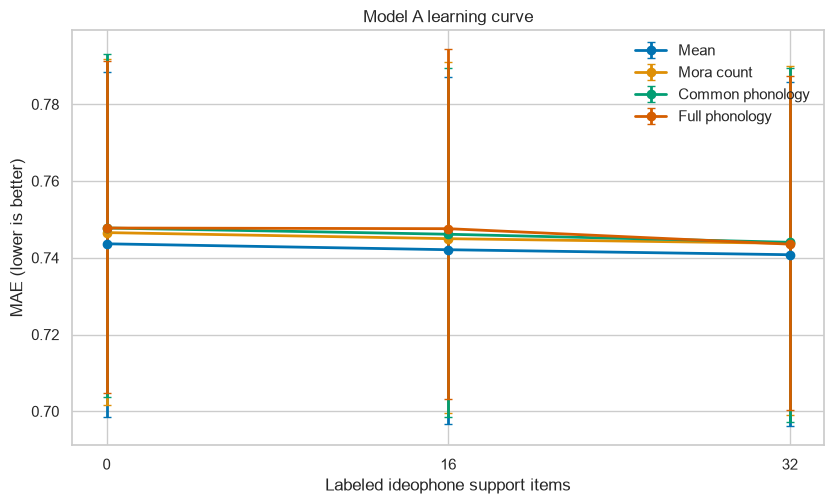

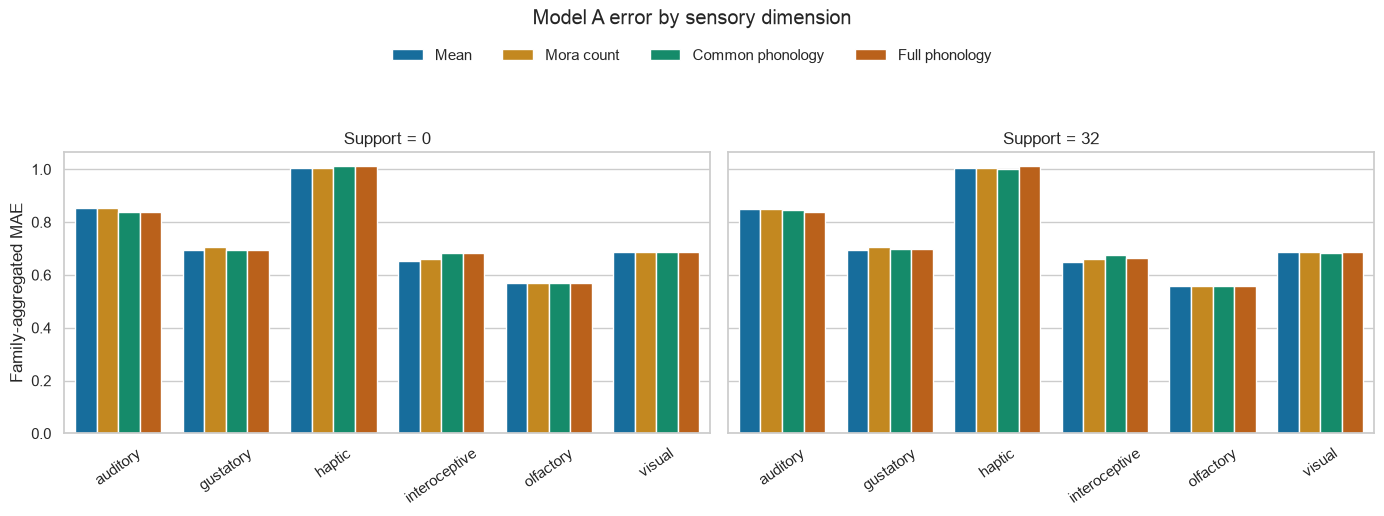

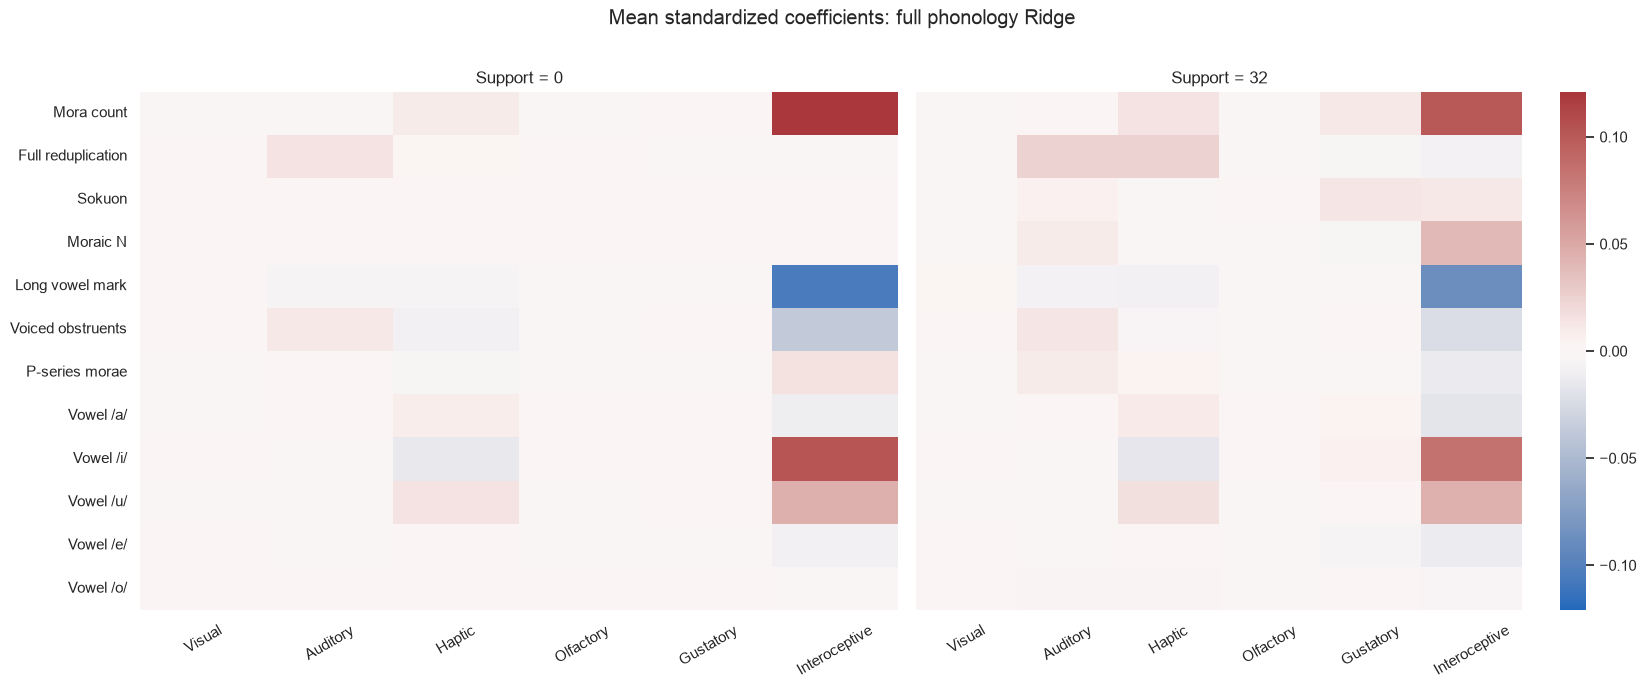

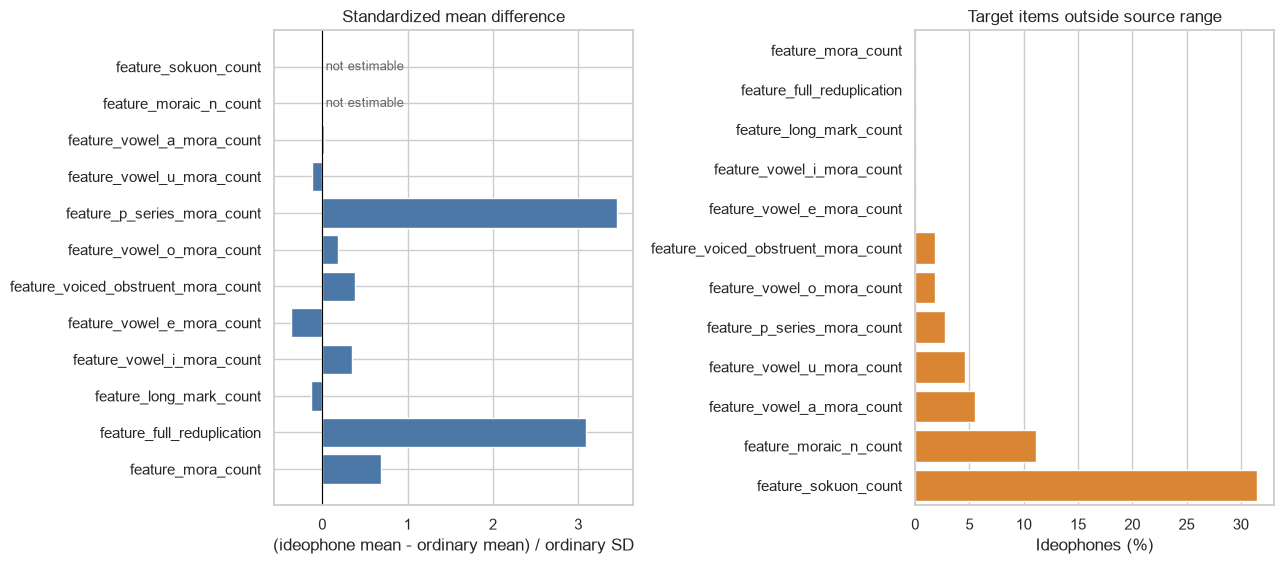

In [7]:
MODEL_ORDER = list(MODEL_FEATURES)
MODEL_LABELS = {
    "mean_baseline": "Mean",
    "ridge_mora_only": "Mora count",
    "ridge_phonology_common": "Common phonology",
    "ridge_phonology_full": "Full phonology",
}
COLORS = dict(zip(MODEL_ORDER, sns.color_palette("colorblind", len(MODEL_ORDER))))

# 学习曲线
fig, ax = plt.subplots(figsize=(8.5, 5.2))
overall = bootstrap_summary.query("dimension == 'overall'")
for model in MODEL_ORDER:
    rows = overall.loc[overall["model"] == model].sort_values("support_size")
    errors = np.vstack([
        rows["mae"].to_numpy() - rows["ci95_low"].to_numpy(),
        rows["ci95_high"].to_numpy() - rows["mae"].to_numpy(),
    ])
    ax.errorbar(
        rows["support_size"], rows["mae"], yerr=errors,
        marker="o", capsize=3, linewidth=2, label=MODEL_LABELS[model], color=COLORS[model]
    )
ax.set(xlabel="Labeled ideophone support items", ylabel="MAE (lower is better)", xticks=SUPPORT_SIZES)
ax.set_title("Model A learning curve")
ax.legend(frameon=False, loc="best")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "model_a_learning_curve.png", dpi=220)
plt.show()

# 分维度结果：0 与 32 样本
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
for ax, support_size in zip(axes, [0, 32]):
    rows = bootstrap_summary.query("dimension != 'overall' and support_size == @support_size").copy()
    rows["model"] = pd.Categorical(rows["model"], MODEL_ORDER, ordered=True)
    sns.barplot(data=rows, x="dimension", y="mae", hue="model", palette=COLORS, ax=ax)
    ax.set_title(f"Support = {support_size}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=35)
    if ax is axes[0]:
        ax.set_ylabel("Family-aggregated MAE")
    else:
        ax.set_ylabel("")
    ax.legend_.remove()
handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle("Model A error by sensory dimension", y=0.99)
fig.legend(
    handles, [MODEL_LABELS.get(x, x) for x in labels],
    loc="upper center", bbox_to_anchor=(0.5, 0.94), ncol=4, frameon=False
)
fig.tight_layout(rect=(0, 0, 1, 0.86))
fig.savefig(FIGURES_DIR / "model_a_dimension_mae.png", dpi=220, bbox_inches="tight")
plt.show()

# 全特征 Ridge 的标准化系数
coef_mean = (
    coefficients.query("model == 'ridge_phonology_full' and support_size in [0, 32]")
    .groupby(["support_size", "dimension", "feature"], as_index=False)["standardized_coefficient"].mean()
)
vmax = max(0.01, coef_mean["standardized_coefficient"].abs().max())
feature_labels = {
    "feature_mora_count": "Mora count",
    "feature_full_reduplication": "Full reduplication",
    "feature_sokuon_count": "Sokuon",
    "feature_moraic_n_count": "Moraic N",
    "feature_long_mark_count": "Long vowel mark",
    "feature_voiced_obstruent_mora_count": "Voiced obstruents",
    "feature_p_series_mora_count": "P-series morae",
    "feature_vowel_a_mora_count": "Vowel /a/",
    "feature_vowel_i_mora_count": "Vowel /i/",
    "feature_vowel_u_mora_count": "Vowel /u/",
    "feature_vowel_e_mora_count": "Vowel /e/",
    "feature_vowel_o_mora_count": "Vowel /o/",
}
dimension_labels = {name: name.capitalize() for name in DIMENSION_NAMES}
fig, axes = plt.subplots(1, 2, figsize=(17, 6.8), sharey=True)
for ax, support_size in zip(axes, [0, 32]):
    matrix = coef_mean.query("support_size == @support_size").pivot(
        index="feature", columns="dimension", values="standardized_coefficient"
    ).reindex(index=FULL_FEATURES, columns=DIMENSION_NAMES)
    matrix = matrix.rename(index=feature_labels, columns=dimension_labels)
    sns.heatmap(matrix, cmap="vlag", center=0, vmin=-vmax, vmax=vmax, ax=ax, cbar=ax is axes[1])
    ax.set_title(f"Support = {support_size}")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Mean standardized coefficients: full phonology Ridge", y=1.01)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "model_a_coefficients.png", dpi=220, bbox_inches="tight")
plt.show()

# 普通词到拟声拟态词的输入分布变化
plot_shift = feature_shift.sort_values("ideophones_outside_ordinary_range_pct")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
shift_values = plot_shift["standardized_mean_difference"].fillna(0).to_numpy()
shift_colors = ["#4C78A8" if available else "#BDBDBD" for available in plot_shift["available_in_zero_shot"]]
axes[0].barh(plot_shift["feature"], shift_values, color=shift_colors)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Standardized mean difference")
axes[0].set_xlabel("(ideophone mean - ordinary mean) / ordinary SD")
axes[0].set_ylabel("")
for y, available in enumerate(plot_shift["available_in_zero_shot"]):
    if not available:
        axes[0].text(0.04, y, "not estimable", va="center", color="#666666", fontsize=9)
sns.barplot(data=plot_shift, y="feature", x="ideophones_outside_ordinary_range_pct", color="#F58518", ax=axes[1])
axes[1].set_title("Target items outside source range")
axes[1].set_xlabel("Ideophones (%)")
axes[1].set_ylabel("")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "model_a_feature_shift.png", dpi=220, bbox_inches="tight")
plt.show()


## 7. 结果检查 / Final checks


In [8]:
expected_models = set(MODEL_FEATURES)
assert set(predictions["model"]) == expected_models
assert set(predictions["support_size"]) == {0, 16, 32}
assert predictions[["y_true", "y_pred", "absolute_error"]].notna().all().all()
assert bootstrap_summary[["mae", "ci95_low", "ci95_high"]].notna().all().all()
assert (bootstrap_summary["ci95_low"] <= bootstrap_summary["mae"]).all()
assert (bootstrap_summary["mae"] <= bootstrap_summary["ci95_high"]).all()

alpha_edge = run_metrics.loc[
    run_metrics["model"].ne("mean_baseline")
    & run_metrics["best_alpha"].isin([ALPHAS.min(), ALPHAS.max()])
]

print(f"Analysis status: {ANALYSIS_STATUS}")
print(f"Runs selecting an alpha-grid edge: {len(alpha_edge)} / {(run_metrics['model'] != 'mean_baseline').sum()}")
print("Files saved to:", RESULTS_DIR, "and", FIGURES_DIR)

bootstrap_summary.query("dimension == 'overall'").pivot(
    index="model", columns="support_size", values=["mae", "ci95_low", "ci95_high"]
)


Analysis status: provisional_candidate_families
Runs selecting an alpha-grid edge: 1380 / 2214
Files saved to: /Users/Nathan/Documents/ChatGPT/日语拟声词/results and /Users/Nathan/Documents/ChatGPT/日语拟声词/figures


mae                      ci95_low            \
support_size                  0         16        32        0         16   
model                                                                      
mean_baseline           0.743641  0.742100  0.740795  0.698396  0.696707   
ridge_mora_only         0.746563  0.744976  0.743762  0.701735  0.699513   
ridge_phonology_common  0.747758  0.746132  0.744033  0.703676  0.698401   
ridge_phonology_full    0.747758  0.747580  0.743545  0.704859  0.703130   

                                 ci95_high                      
support_size                  32        0         16        32  
model                                                           
mean_baseline           0.696054  0.788464  0.787084  0.785759  
ridge_mora_only         0.699015  0.791868  0.790955  0.789921  
ridge_phonology_common  0.697205  0.793005  0.789360  0.789544  
ridge_phonology_full    0.700298  0.791212  0.794318  0.787270

### 解释边界 / Interpretation boundary

- 这项分析检验的是预测与迁移关系，不能单独证明某个音造成某种人类感觉。
- `0-shot` 表示没有使用本数据集中的拟声拟态词评分训练 Ridge。
- 正式投稿前必须确认词族划分；确认前的数值用于检查流程与确定实验设计。
- 模型 B、C 必须复用同一外层测试折、同一支持样本清单和同一评价方法，才能公平比较。
